# Ventas de videojuegos: patrones de éxito comercial
## Primera entrega · Data Science II
**Autor:** Mauro Fetingis · **Institución:** Coderhouse · **Fecha:** 10 de noviembre de 2026

**Obtención de insights a partir de visualizaciones**

Este trabajo retoma el dataset de Data Science I y reconstruye el análisis con resultados calculados, controles de calidad y descarga reproducible desde una API pública. El alcance de esta instancia es exploratorio. El entrenamiento y la optimización de modelos quedan para las siguientes entregas.

### Cómo ejecutar
En Colab, subir este notebook y `dataset data science.csv` al entorno. En Jupyter, ubicarlos en la misma carpeta y ejecutar todas las celdas en orden. La descarga de Kaggle queda activada para verificar la fuente. Con los datos ya descargados puede cambiarse `DESCARGAR_FUENTE = False`. Si la red falla, el análisis puede continuar con el CSV local y muestra claramente el estado de verificación.

## 1. Abstracto, motivación y audiencia
La decisión de publicar un videojuego requiere comprender cómo varían las ventas según el género, la plataforma y el mercado de destino. Este proyecto analiza un conjunto histórico de registros de ventas para describir esas diferencias y distinguir el volumen total de una categoría del rendimiento por lanzamiento. La motivación personal combina el interés por los videojuegos y el análisis de datos.

La audiencia son responsables de publicación, marketing y planificación comercial de estudios y distribuidoras. El análisis puede ayudarles a formular preguntas sobre segmentación regional y composición del catálogo. Su cobertura histórica limita el uso para decisiones actuales: los hallazgos deberán contrastarse con datos recientes, presupuestos y rentabilidad.

La unidad de análisis es el **registro de un videojuego en una plataforma**, no necesariamente un juego único. Las ventas se expresan en **millones de unidades**, no en dólares. Se aplican controles de tipos, faltantes, duplicados y consistencia, se crean variables derivadas y se comparan distribuciones, agregaciones y participaciones regionales. Las conclusiones describen asociaciones dentro de la muestra y no prueban causalidad.

## 2. Pregunta de negocio e hipótesis
**¿Qué patrones históricos de ventas por género, plataforma y región pueden orientar la evaluación comercial de un catálogo de videojuegos?**

| ID | Pregunta | Hipótesis descriptiva |
|---|---|---|
| P1 / H1 | ¿Qué géneros lideran en volumen y qué cambia al mirar cada lanzamiento? | Action y Sports lideran en ventas acumuladas. |
| P2 / H2 | ¿Qué plataformas y editores concentran las ventas? | Nintendo lidera las ventas acumuladas por editor. |
| P3 / H3 | ¿Cómo cambia la composición de ventas por género entre regiones? | Role-Playing tiene mayor participación dentro de Japón que dentro de NA y Europa. |
| P4 / H4 | ¿Qué cohortes de lanzamiento acumulan más ventas? | Los lanzamientos de 2000–2009 concentran la mayor suma. |
| P5 / H5 | ¿Qué tan frecuente es alcanzar un millón de unidades? | Menos del 20 % de los registros alcanza ese umbral. |

Las hipótesis se contrastan descriptivamente en este dataset. No se realizan inferencias sobre todos los videojuegos del mercado. El umbral de un millón es una definición operativa para este proyecto, no una medida de rentabilidad.

In [1]:
from pathlib import Path
import io, json, zipfile, hashlib, platform
from datetime import datetime, timezone
from urllib.request import urlopen, Request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ARCHIVO = Path("dataset data science.csv")
SALIDAS = Path("resultados"); SALIDAS.mkdir(exist_ok=True)
GRAFICOS = Path("graficos"); GRAFICOS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 5.5), "figure.dpi": 125,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 14,
    "axes.labelsize": 11, "font.size": 10})
AZUL, VERDE, NARANJA = "#245C91", "#16877B", "#DC8541"
def guardar(nombre):
    plt.tight_layout()
    plt.savefig(GRAFICOS / f"{nombre}.png", dpi=180, bbox_inches="tight")
    plt.show()
def nota(texto): display(Markdown(texto))
print("Python", platform.python_version(), "· pandas", pd.__version__, "· numpy", np.__version__)

Python 3.12.14 · pandas 3.1.1 · numpy 2.5.4


## 3. Obtención de datos desde una API pública
**Fuente:** [Video Game Sales, Gregor Gregory (gregorut), Kaggle](https://www.kaggle.com/datasets/gregorut/videogamesales).
**Endpoint:** `https://www.kaggle.com/api/v1/datasets/download/gregorut/videogamesales`.

Se descarga el ZIP, se lee el CSV sin extraer rutas arbitrarias y se guarda una copia local como `resultados/vgsales_fuente.csv`. Se conserva el CSV original con el nombre indicado por el autor. La comparación exige mismas dimensiones, columnas, orden y valores; un cambio en la fuente no reemplaza silenciosamente la base del análisis. El manifiesto guarda URL, fecha, hash del archivo de trabajo y estado de descarga.

In [2]:
DESCARGAR_FUENTE = True
URL = "https://www.kaggle.com/api/v1/datasets/download/gregorut/videogamesales"
fuente = SALIDAS / "vgsales_fuente.csv"
estado = "No se solicitó descarga"
if DESCARGAR_FUENTE:
    try:
        req = Request(URL, headers={"User-Agent": "Mozilla/5.0"})
        with urlopen(req, timeout=60) as response:
            contenido = response.read()
        with zipfile.ZipFile(io.BytesIO(contenido)) as z:
            nombres = [n for n in z.namelist() if Path(n).name == "vgsales.csv"]
            if len(nombres) != 1:
                raise ValueError("El ZIP no contiene un único vgsales.csv")
            fuente.write_bytes(z.read(nombres[0]))
        estado = "Descarga pública completada"
    except Exception as exc:
        estado = f"Descarga no completada: {type(exc).__name__}: {exc}"
        print(estado)
        if not ARCHIVO.exists():
            raise RuntimeError("Subir dataset data science.csv o restablecer la descarga") from exc
if not ARCHIVO.exists() and fuente.exists():
    ARCHIVO.write_bytes(fuente.read_bytes())
if not ARCHIVO.exists():
    raise FileNotFoundError("Subí dataset data science.csv a la carpeta del notebook")
raw = pd.read_csv(ARCHIVO)
coincide = None
if fuente.exists():
    df_fuente = pd.read_csv(fuente)
    coincide = raw.equals(df_fuente)
    print("Coincidencia exacta del CSV de trabajo con la copia de la fuente:", coincide)
    if not coincide:
        print("La fuente difiere. Se conserva el CSV de trabajo para mantener la versión analizada.")
manifiesto = {"archivo": str(ARCHIVO), "fuente": URL,
    "fecha_verificacion_utc": datetime.now(timezone.utc).isoformat(),
    "sha256_archivo": hashlib.sha256(ARCHIVO.read_bytes()).hexdigest(),
    "estado_descarga": estado, "coincidencia_con_copia_fuente": coincide,
    "filas": len(raw), "columnas": len(raw.columns)}
(SALIDAS / "manifiesto_fuente.json").write_text(json.dumps(manifiesto, indent=2, ensure_ascii=False), encoding="utf-8")
print(estado)
print(f"Archivo de trabajo: {ARCHIVO} | {raw.shape[0]:,} filas x {raw.shape[1]} columnas")
display(raw.head())

Coincidencia exacta del CSV de trabajo con la copia de la fuente: True
Descarga pública completada
Archivo de trabajo: dataset data science.csv | 16,598 filas x 11 columnas


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


## 4. Metadata y diccionario de variables
| Columna | Tipo conceptual | Significado |
|---|---|---|
| Rank | Ordinal | Posición en el ranking de ventas de la fuente |
| Name | Texto | Nombre del videojuego |
| Platform | Categórica | Plataforma de lanzamiento |
| Year | Temporal | Año de lanzamiento, con valores faltantes |
| Genre | Categórica | Género del videojuego |
| Publisher | Categórica | Editor o distribuidor, con valores faltantes |
| NA_Sales | Numérica | Ventas en Norteamérica, millones de unidades |
| EU_Sales | Numérica | Ventas en Europa, millones de unidades |
| JP_Sales | Numérica | Ventas en Japón, millones de unidades |
| Other_Sales | Numérica | Ventas en otras regiones, millones de unidades |
| Global_Sales | Numérica | Ventas globales, millones de unidades |

El rango de años observado no demuestra cobertura completa de cada año. Las ventas son acumuladas por registro: sumar por año de lanzamiento **no equivale a ventas realizadas durante ese año**. La fuente no aporta costos, beneficios, inversión publicitaria ni una fecha de corte individual por juego.

In [3]:
metadata = pd.DataFrame({"tipo_original": raw.dtypes.astype(str),
    "faltantes": raw.isna().sum(), "faltantes_pct": raw.isna().mean().mul(100),
    "valores_distintos": raw.nunique()})
display(metadata.round(2))
display(raw.describe().round(3))
print("Nombres distintos:", raw.Name.nunique(), "| Plataformas:", raw.Platform.nunique(), "| Géneros:", raw.Genre.nunique())

Nombres distintos: 11493 | Plataformas: 31 | Géneros: 12


,tipo_original,faltantes,faltantes_pct,valores_distintos
Rank,int64,0,0.00,16598
Name,str,0,0.00,11493
Platform,str,0,0.00,31
Year,float64,271,1.63,39
Genre,str,0,0.00,12
Publisher,str,58,0.35,578
NA_Sales,float64,0,0.00,409
EU_Sales,float64,0,0.00,305
JP_Sales,float64,0,0.00,244
Other_Sales,float64,0,0.00,157


,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000,16327.000,16598.000,16598.000,16598.000,16598.000,16598.000
mean,8300.605,2006.406,0.265,0.147,0.078,0.048,0.537
std,4791.854,5.829,0.817,0.505,0.309,0.189,1.555
min,1.000,1980.000,0.000,0.000,0.000,0.000,0.010
25%,4151.250,2003.000,0.000,0.000,0.000,0.000,0.060
50%,8300.500,2007.000,0.080,0.020,0.000,0.010,0.170
75%,12449.750,2010.000,0.240,0.110,0.040,0.040,0.470
max,16600.000,2020.000,41.490,29.020,10.220,10.570,82.740


## 5. Limpieza, validación y decisiones
- Se conserva `raw` sin modificar y se trabaja sobre una copia.
- Se eliminan duplicados completos si existen. Los registros con igual nombre y plataforma se inspeccionan y se conservan cuando tienen datos distintos: la clave no basta para justificar una eliminación.
- Se normalizan espacios en textos y se convierten las columnas numéricas. Los años permanecen como enteros anulables.
- `Publisher` faltante se etiqueta como `Desconocido`. Los años faltantes no se imputan para describir el tiempo: se excluyen únicamente del análisis temporal.
- Se verifican ventas no negativas y se compara la suma regional con el total global. Se toleran hasta 0,03 millones de diferencia absoluta por redondeo, sin reemplazar las cifras originales.
- Los grandes éxitos se conservan. La asimetría se aborda con mediana, percentiles y visualización logarítmica, sin borrar observaciones legítimas.

In [4]:
df = raw.copy()
for col in ["Name", "Platform", "Genre", "Publisher"]:
    df[col] = df[col].astype("string").str.strip().replace("", pd.NA)
ventas = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]
for col in ["Rank", "Year"] + ventas:
    df[col] = pd.to_numeric(df[col], errors="raise")
assert df[ventas].notna().all().all(), "Hay ventas faltantes"
assert df[ventas].ge(0).all().all(), "Hay ventas negativas"
assert (df.Year.dropna() % 1 == 0).all(), "Hay años no enteros"
assert df[["Name", "Platform", "Genre"]].notna().all().all()
antes = len(df)
df = df.drop_duplicates().copy()
df["Year"] = df["Year"].astype("Int64")
df["Publisher"] = df["Publisher"].fillna("Desconocido")
df["Diferencia_Redondeo"] = df[ventas[:-1]].sum(axis=1) - df.Global_Sales
assert df.Diferencia_Redondeo.abs().max() <= 0.030001
repetidos = df.duplicated(["Name", "Platform"], keep=False)
print("Duplicados completos eliminados:", antes-len(df))
print("Filas con clave Name + Platform repetida:", repetidos.sum())
display(df.loc[repetidos, ["Name", "Platform", "Year", "Genre", "Publisher", "Global_Sales"]])
print("Mayor diferencia por redondeo (M):", round(df.Diferencia_Redondeo.abs().max(), 3))
print("Años faltantes:", df.Year.isna().sum())

Duplicados completos eliminados: 0
Filas con clave Name + Platform repetida: 10
Mayor diferencia por redondeo (M): 0.02
Años faltantes: 271


,Name,Platform,Year,Genre,Publisher,Global_Sales
603,Madden NFL 13,PS3,2012,Sports,Electronic Arts,2.56
1173,Need for Speed: Most Wanted,X360,2012,Racing,Electronic Arts,1.58
1530,Need for Speed: Most Wanted,X360,2005,Racing,Electronic Arts,1.29
1715,Sonic the Hedgehog,PS3,2006,Platform,Sega,1.18
4145,Sonic the Hedgehog,PS3,<NA>,Platform,Desconocido,0.48
5900,Need for Speed: Most Wanted,PC,2005,Racing,Electronic Arts,0.30
11676,Need for Speed: Most Wanted,PC,2012,Racing,Electronic Arts,0.08
14997,Wii de Asobu: Metroid Prime,Wii,<NA>,Shooter,Nintendo,0.02
14999,Wii de Asobu: Metroid Prime,Wii,<NA>,Shooter,Nintendo,0.02
16127,Madden NFL 13,PS3,2012,Sports,Electronic Arts,0.01


### Enriquecimiento mediante variables derivadas
Se añaden `Decada`, `Exito_1M`, `Log_Ventas`, `Region_Principal` y `Cuota_Japon`. No se añade un cruce externo sin una clave confiable: el requisito de adquisición se cubre con la API pública de Kaggle. Las sugerencias de enriquecimiento externo quedan como extensión posible.

`Exito_1M` indica ventas globales mayores o iguales a un millón. `Region_Principal` usa el máximo de las cuatro regiones, marcando empates. Las cuotas usan la suma regional como denominador para evitar diferencias de redondeo con el total global.

In [5]:
df["Decada"] = (df.Year // 10 * 10).astype("Int64")
df["Exito_1M"] = df.Global_Sales.ge(1).astype(int)
df["Log_Ventas"] = np.log1p(df.Global_Sales)
regiones = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]
rotulos = {"NA_Sales": "Norteamérica", "EU_Sales": "Europa", "JP_Sales": "Japón", "Other_Sales": "Otras"}
maximos = df[regiones].eq(df[regiones].max(axis=1), axis=0)
df["Region_Principal"] = df[regiones].idxmax(axis=1).map(rotulos)
df.loc[maximos.sum(axis=1).gt(1), "Region_Principal"] = "Empate"
df["Cuota_Japon"] = df.JP_Sales.div(df[regiones].sum(axis=1).replace(0, np.nan))
df_temporal = df.dropna(subset=["Year"]).copy()
df.to_csv(SALIDAS / "videojuegos_limpio.csv", index=False)
metadata.to_csv(SALIDAS / "metadata_original.csv")
print(f"Base enriquecida: {df.shape[0]:,} filas x {df.shape[1]} columnas")
print(f"Base temporal: {len(df_temporal):,} registros con año conocido")
display(df[["Name", "Decada", "Exito_1M", "Log_Ventas", "Region_Principal", "Cuota_Japon"]].head())

Base enriquecida: 16,598 filas x 17 columnas
Base temporal: 16,327 registros con año conocido


,Name,Decada,Exito_1M,Log_Ventas,Region_Principal,Cuota_Japon
0,Wii Sports,2000,1,4.427717,Norteamérica,0.045564
1,Super Mario Bros.,1980,1,3.719409,Norteamérica,0.169235
2,Mario Kart Wii,2000,1,3.606041,Norteamérica,0.105777
3,Wii Sports Resort,2000,1,3.526361,Norteamérica,0.099394
4,Pokemon Red/Pokemon Blue,1990,1,3.477232,Norteamérica,0.325685


## 6. EDA: distribución y concentración de ventas (P5 / H5)
Comparamos la media y la mediana. La escala logarítmica permite observar registros pequeños y grandes sin eliminar los éxitos extremos. La curva de concentración ordena los registros de mayor a menor venta y calcula su contribución acumulada.

,Millones de unidades
count,16598.000
mean,0.537
std,1.555
min,0.010
25%,0.060
50%,0.170
75%,0.470
90%,1.210
95%,2.040
99%,5.431


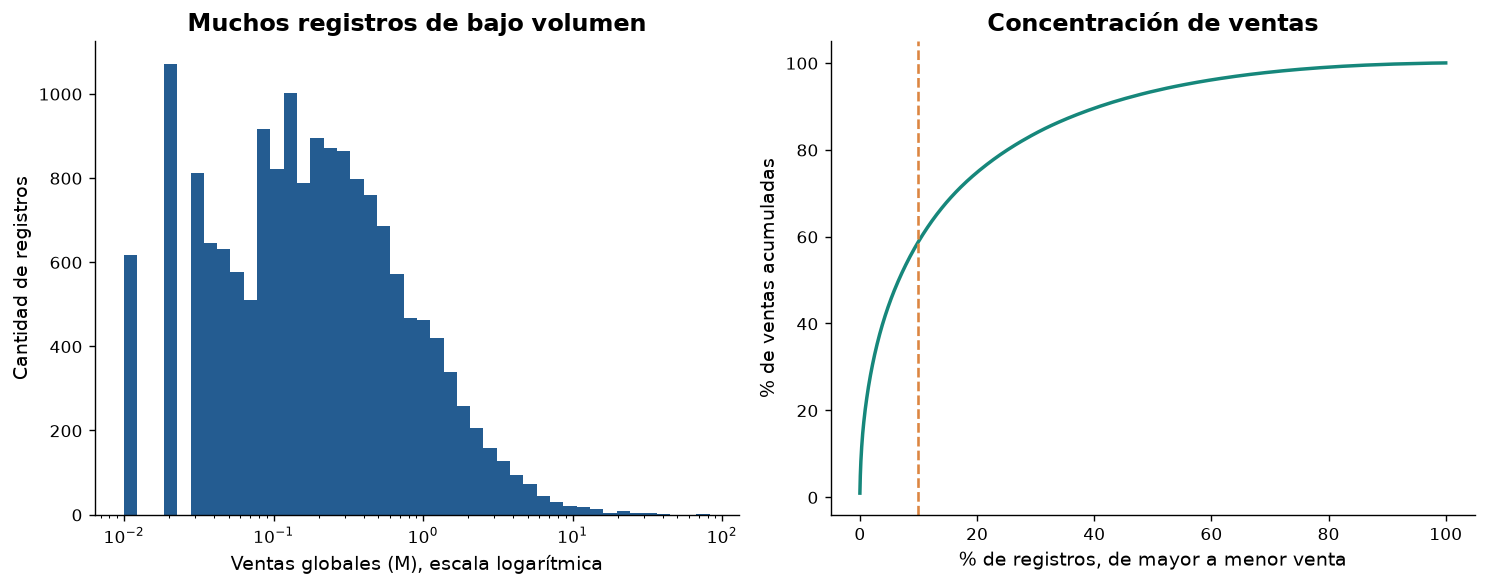

**Hallazgo P5:** la mediana es 0.17 M y la media 0.54 M. El 12.54 % alcanza al menos 1 M, por lo que H5 se respalda descriptivamente. El 10 % superior (1,660 registros, redondeado hacia arriba) concentra el 58.9 % de las ventas. El promedio aislado sobreestima el resultado típico.

In [6]:
resumen = df.Global_Sales.describe(percentiles=[.25,.5,.75,.9,.95,.99])
display(resumen.to_frame("Millones de unidades").round(3))
tasa = df.Exito_1M.mean()*100
orden = df.Global_Sales.sort_values(ascending=False).to_numpy()
n_top = int(np.ceil(len(df)*.1))
cuota_top10 = orden[:n_top].sum()/orden.sum()*100
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].hist(df.Global_Sales, bins=np.geomspace(df.Global_Sales.min(), df.Global_Sales.max(), 45), color=AZUL)
axes[0].set_xscale("log"); axes[0].set_xlabel("Ventas globales (M), escala logarítmica")
axes[0].set_ylabel("Cantidad de registros"); axes[0].set_title("Muchos registros de bajo volumen")
axes[1].plot(np.arange(1,len(df)+1)/len(df)*100, np.cumsum(orden)/orden.sum()*100, color=VERDE, linewidth=2)
axes[1].axvline(10, color=NARANJA, linestyle="--")
axes[1].set(xlabel="% de registros, de mayor a menor venta", ylabel="% de ventas acumuladas", title="Concentración de ventas")
guardar("01_distribucion")
nota(f"**Hallazgo P5:** la mediana es {df.Global_Sales.median():.2f} M y la media {df.Global_Sales.mean():.2f} M. El {tasa:.2f} % alcanza al menos 1 M, por lo que H5 se respalda descriptivamente. El 10 % superior ({n_top:,} registros, redondeado hacia arriba) concentra el {cuota_top10:.1f} % de las ventas. El promedio aislado sobreestima el resultado típico.")

## 7. Géneros: volumen y rendimiento por registro (P1 / H1)
Una categoría puede acumular más ventas por tener más lanzamientos. Por eso se contrastan total, cantidad, media y mediana. No se comparan presupuestos ni rentabilidad, porque no están disponibles.

,registros,total,media,mediana,tasa_1m
Genre,,,,,
Action,3316,1751.18,0.528,0.190,0.128
Sports,2346,1330.93,0.567,0.220,0.129
Shooter,1310,1037.37,0.792,0.230,0.192
Role-Playing,1488,927.37,0.623,0.185,0.136
Platform,886,831.37,0.938,0.280,0.220
Misc,1739,809.96,0.466,0.160,0.099
Racing,1249,732.04,0.586,0.190,0.146
Fighting,848,448.91,0.529,0.210,0.146
Simulation,867,392.20,0.452,0.160,0.107


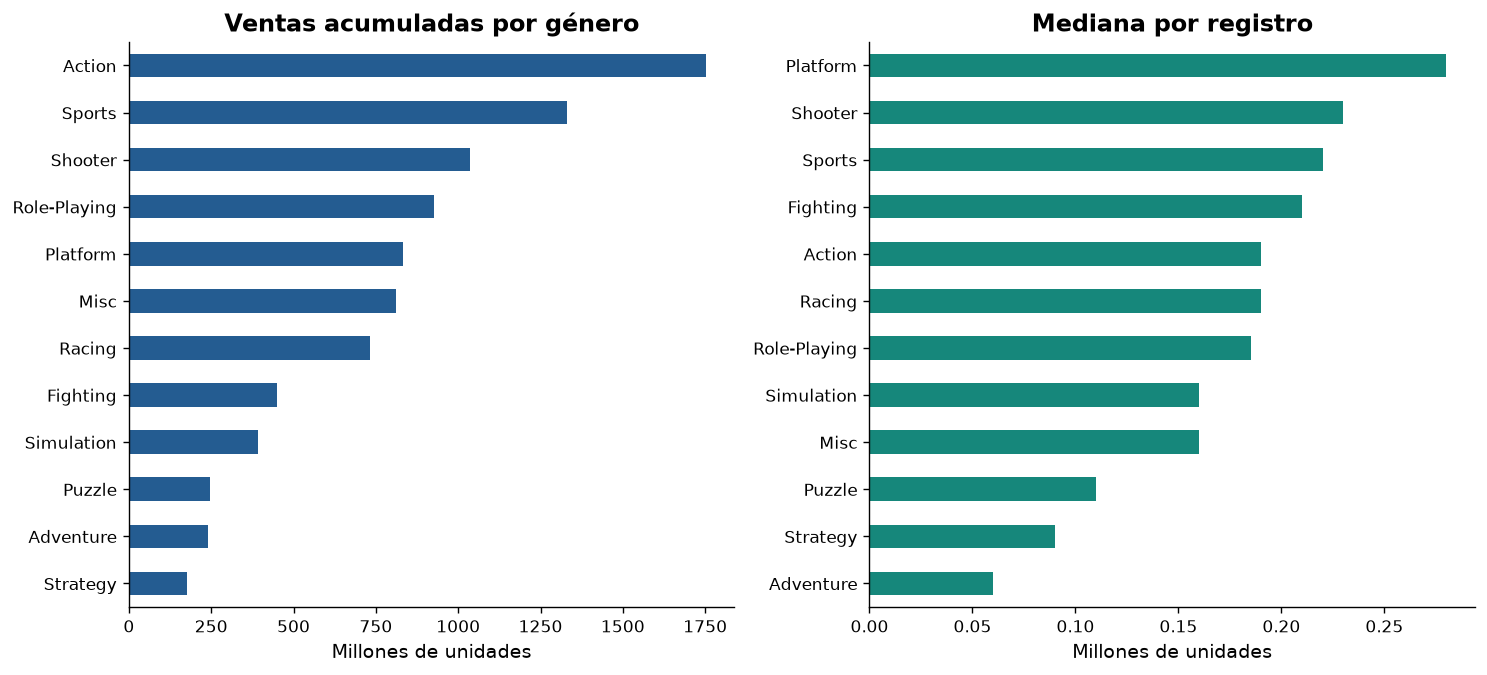

**Hallazgo P1:** Action y Sports lideran en volumen, con 1,751.18 M y 1,330.93 M. H1 se respalda. La mayor media corresponde a Platform (0.94 M) y la mayor mediana a Platform (0.28 M). Volumen agregado y resultado típico requieren lecturas distintas.

In [7]:
generos = df.groupby("Genre").agg(registros=("Global_Sales","size"),
    total=("Global_Sales","sum"), media=("Global_Sales","mean"),
    mediana=("Global_Sales","median"), tasa_1m=("Exito_1M","mean")).sort_values("total",ascending=False)
display(generos.round(3))
fig, axes = plt.subplots(1,2,figsize=(12,5.5))
generos.total.sort_values().plot.barh(ax=axes[0],color=AZUL)
axes[0].set(title="Ventas acumuladas por género",xlabel="Millones de unidades",ylabel="")
generos.mediana.sort_values().plot.barh(ax=axes[1],color=VERDE)
axes[1].set(title="Mediana por registro",xlabel="Millones de unidades",ylabel="")
guardar("02_generos")
nota(f"**Hallazgo P1:** {generos.index[0]} y {generos.index[1]} lideran en volumen, con {generos.total.iloc[0]:,.2f} M y {generos.total.iloc[1]:,.2f} M. H1 se respalda. La mayor media corresponde a {generos.media.idxmax()} ({generos.media.max():.2f} M) y la mayor mediana a {generos.mediana.idxmax()} ({generos.mediana.max():.2f} M). Volumen agregado y resultado típico requieren lecturas distintas.")

## 8. Plataformas y editores (P2 / H2)
Se muestran los ocho primeros de cada grupo por legibilidad. Las tablas exportadas conservan todos los grupos. Los totales no controlan la antigüedad de las plataformas, la cantidad de lanzamientos ni los juegos incluidos con hardware.

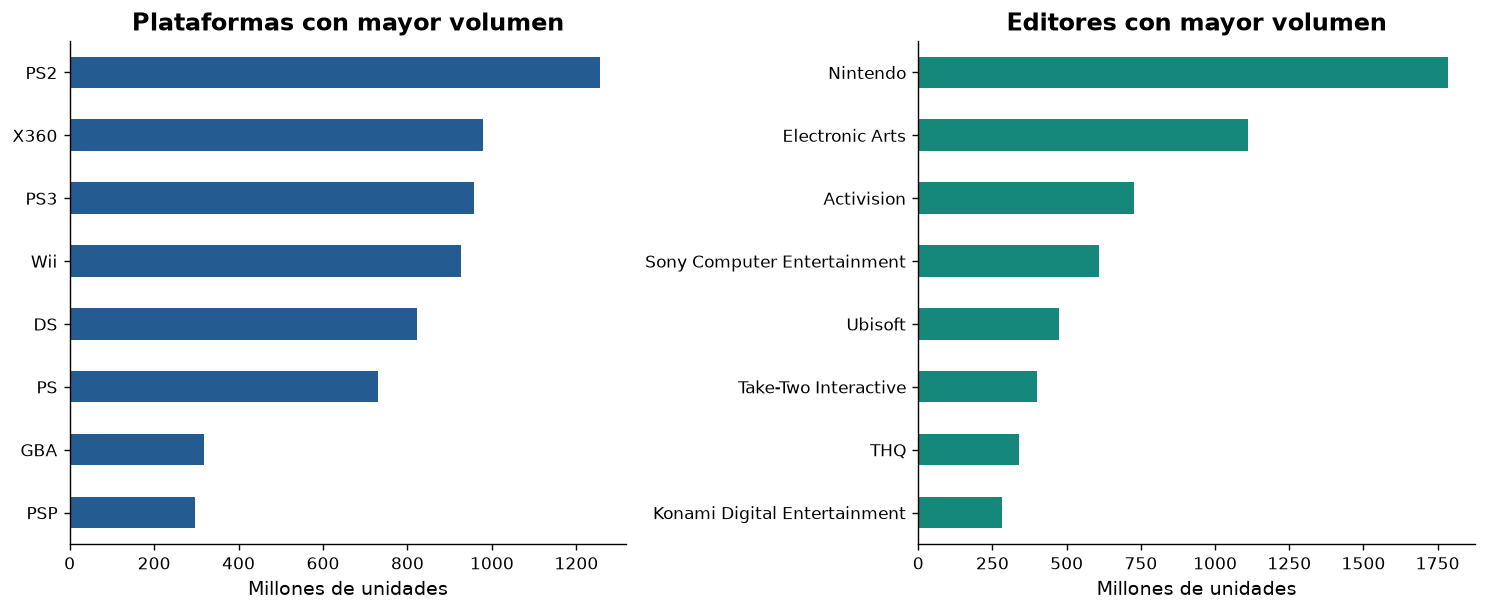

**Hallazgo P2:** PS2 lidera plataformas (1,255.64 M). Nintendo lidera editores (1,786.56 M). Nintendo representa el 20.0 % del total registrado, lo que respalda H2. Esto no equivale a su cuota del mercado actual.

In [8]:
plataformas = df.groupby("Platform").Global_Sales.sum().sort_values(ascending=False)
editores = df.groupby("Publisher").Global_Sales.sum().sort_values(ascending=False)
fig, axes = plt.subplots(1,2,figsize=(12,5))
plataformas.head(8).sort_values().plot.barh(ax=axes[0],color=AZUL)
editores.head(8).sort_values().plot.barh(ax=axes[1],color=VERDE)
for ax in axes: ax.set_xlabel("Millones de unidades"); ax.set_ylabel("")
axes[0].set_title("Plataformas con mayor volumen"); axes[1].set_title("Editores con mayor volumen")
guardar("03_plataformas_editores")
cuota_nintendo=editores.get("Nintendo",0)/df.Global_Sales.sum()*100
nota(f"**Hallazgo P2:** {plataformas.index[0]} lidera plataformas ({plataformas.iloc[0]:,.2f} M). {editores.index[0]} lidera editores ({editores.iloc[0]:,.2f} M). Nintendo representa el {cuota_nintendo:.1f} % del total registrado, lo que respalda H2. Esto no equivale a su cuota del mercado actual.")

## 9. Segmentación regional (P3 / H3)
El mapa de calor utiliza el porcentaje que cada género representa **dentro de cada región**. Cada columna suma 100 %. Este denominador permite comparar composición entre regiones de distinto tamaño. No mide preferencias individuales ni ventas por habitante.

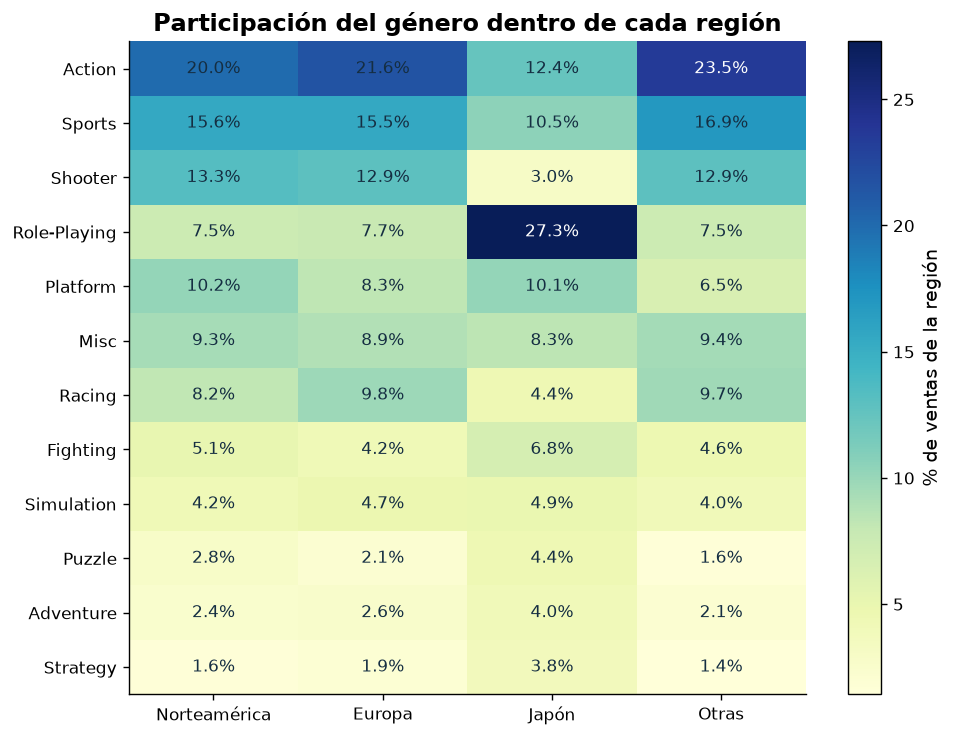

**Hallazgo P3:** Role-Playing representa 27.3 % de las ventas de Japón, frente a 7.5 % en NA y 7.7 % en Europa. H3 se respalda. Norteamérica aporta el 49.3 % de la suma regional total. Una estrategia de catálogo debería investigar por separado cada región antes de extrapolar el liderazgo global.

In [9]:
totales_reg = df[regiones].sum()
cuotas_reg = totales_reg/totales_reg.sum()*100
matriz = df.groupby("Genre")[regiones].sum().reindex(generos.index)
composicion = matriz.div(matriz.sum(axis=0),axis=1)*100
fig, ax = plt.subplots(figsize=(8,6))
im=ax.imshow(composicion.to_numpy(),aspect="auto",cmap="YlGnBu")
ax.set_xticks(range(4),[rotulos[r] for r in regiones])
ax.set_yticks(range(len(composicion)),composicion.index)
for i in range(len(composicion)):
    for j in range(4):
        v=composicion.iloc[i,j]
        ax.text(j,i,f"{v:.1f}%",ha="center",va="center",color="white" if v>22 else "#152E42")
ax.set_title("Participación del género dentro de cada región")
fig.colorbar(im,ax=ax,label="% de ventas de la región")
guardar("04_regiones")
rpg=composicion.loc["Role-Playing"]
nota(f"**Hallazgo P3:** Role-Playing representa {rpg.JP_Sales:.1f} % de las ventas de Japón, frente a {rpg.NA_Sales:.1f} % en NA y {rpg.EU_Sales:.1f} % en Europa. H3 se respalda. Norteamérica aporta el {cuotas_reg.NA_Sales:.1f} % de la suma regional total. Una estrategia de catálogo debería investigar por separado cada región antes de extrapolar el liderazgo global.")

## 10. Cohortes temporales y cobertura (P4 / H4)
Se agrupan ventas acumuladas según el año y la década de lanzamiento. Las décadas tienen diferente cobertura y tiempo de exposición. Los registros sin año no se distribuyen artificialmente entre décadas. Los años posteriores a 2016 tienen muy pocos registros y se muestran explícitamente en la tabla de cobertura.

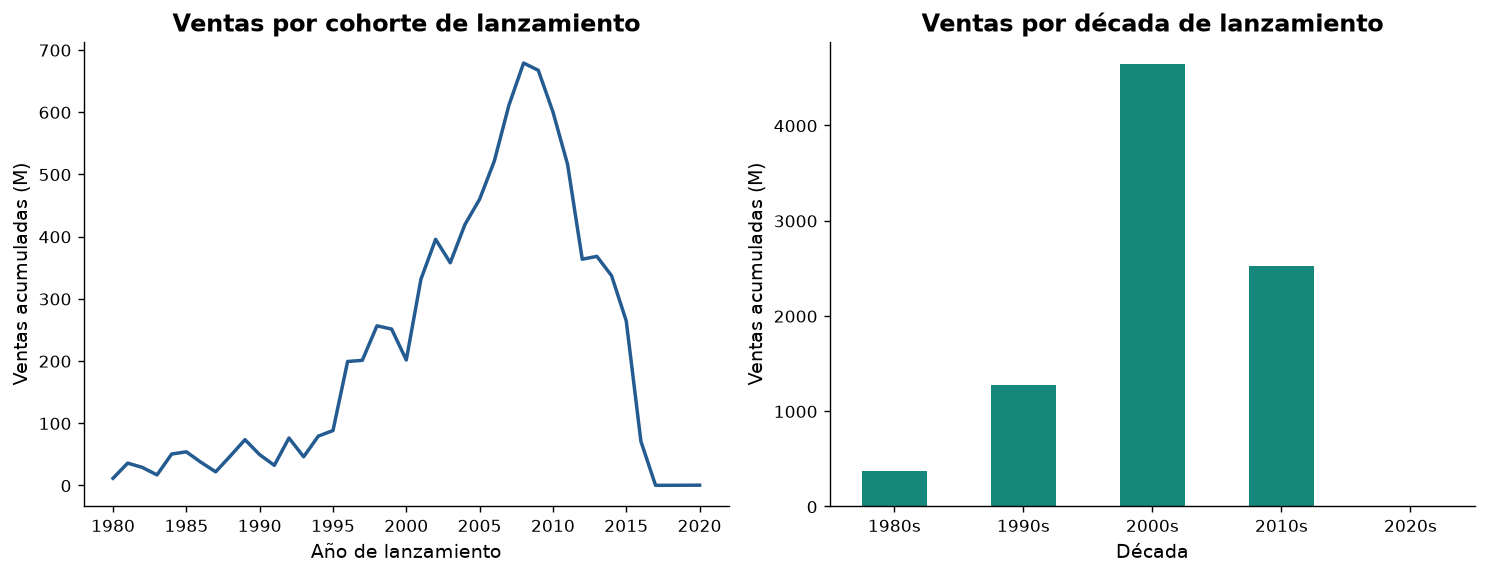

,registros,ventas
Year,,
2009,1431,667.30
2010,1259,600.45
2011,1139,515.99
2012,657,363.54
2013,546,368.11
2014,582,337.05
2015,614,264.44
2016,344,70.93
2017,3,0.05


**Hallazgo P4:** 2000–2009 suma 4,644.02 M, el 52.06 % del total y el 52.65 % de las ventas con año conocido. H4 se respalda. El descenso de cohortes recientes no permite concluir una caída del mercado: se mezclan cobertura y distintos tiempos de acumulación de ventas.

In [10]:
anual=df_temporal.groupby("Year").agg(registros=("Global_Sales","size"),ventas=("Global_Sales","sum"))
decadas=df_temporal.groupby("Decada").Global_Sales.sum()
fig,axes=plt.subplots(1,2,figsize=(12,4.7))
axes[0].plot(anual.index.astype(int),anual.ventas,color=AZUL,linewidth=2)
axes[0].set(title="Ventas por cohorte de lanzamiento",xlabel="Año de lanzamiento",ylabel="Ventas acumuladas (M)")
decadas.rename(index=lambda x:f"{int(x)}s").plot.bar(ax=axes[1],color=VERDE,rot=0)
axes[1].set(title="Ventas por década de lanzamiento",xlabel="Década",ylabel="Ventas acumuladas (M)")
guardar("05_tiempo")
display(anual.tail(10))
cuota_2000=decadas.loc[2000]/df.Global_Sales.sum()*100
cuota_2000_fechados=decadas.loc[2000]/df_temporal.Global_Sales.sum()*100
nota(f"**Hallazgo P4:** 2000–2009 suma {decadas.loc[2000]:,.2f} M, el {cuota_2000:.2f} % del total y el {cuota_2000_fechados:.2f} % de las ventas con año conocido. H4 se respalda. El descenso de cohortes recientes no permite concluir una caída del mercado: se mezclan cobertura y distintos tiempos de acumulación de ventas.")

## 11. Relaciones multivariadas y valores extremos
Se relacionan género, plataforma y ventas acumuladas. Un segundo análisis compara año y ventas por registro. Una correlación débil no demuestra que el año sea irrelevante ni identifica causas alternativas.

Correlación de Pearson año-ventas: -0.075


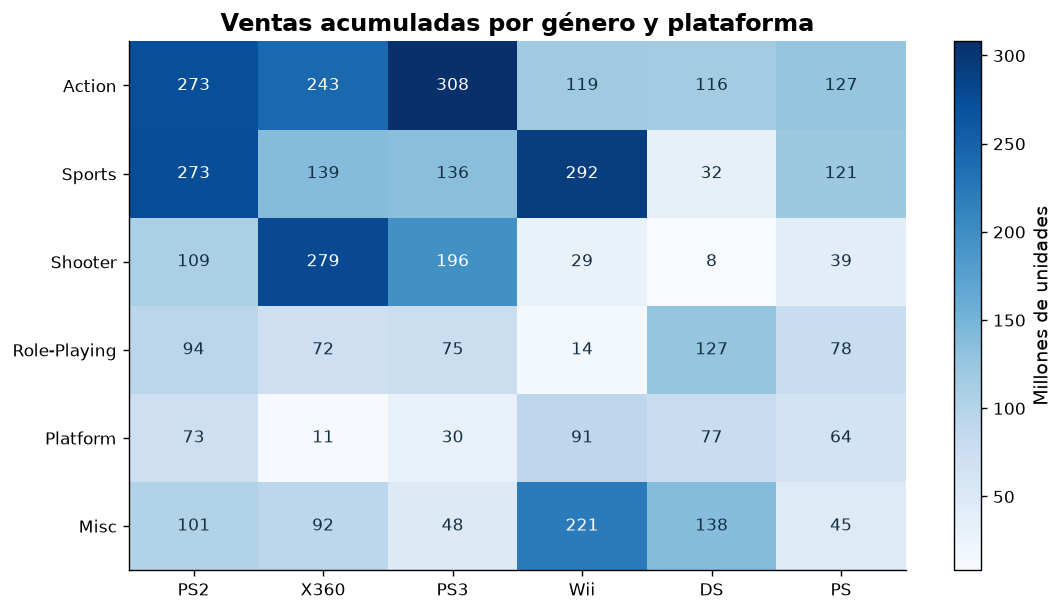

**Interpretación:** el cruce muestra dónde se concentra el volumen de las categorías seleccionadas. No ajusta por cantidad de títulos ni por duración de cada plataforma. Las ventas regionales son componentes del total global: su correlación con ese total no es evidencia independiente de capacidad predictiva.

In [11]:
top_plat=plataformas.head(6).index
top_gen=generos.head(6).index
cruce=df.pivot_table(index="Genre",columns="Platform",values="Global_Sales",aggfunc="sum",fill_value=0).loc[top_gen,top_plat]
fig,ax=plt.subplots(figsize=(9,5))
im=ax.imshow(cruce.to_numpy(),cmap="Blues",aspect="auto")
ax.set_xticks(range(len(top_plat)),top_plat);ax.set_yticks(range(len(top_gen)),top_gen)
for i in range(len(top_gen)):
    for j in range(len(top_plat)):
        v=cruce.iloc[i,j];ax.text(j,i,f"{v:.0f}",ha="center",va="center",color="white" if v>cruce.to_numpy().max()*.6 else "#152E42")
fig.colorbar(im,ax=ax,label="Millones de unidades")
ax.set_title("Ventas acumuladas por género y plataforma")
guardar("06_genero_plataforma")
pearson=df_temporal[["Year","Global_Sales"]].astype(float).corr().iloc[0,1]
print(f"Correlación de Pearson año-ventas: {pearson:.3f}")
nota("**Interpretación:** el cruce muestra dónde se concentra el volumen de las categorías seleccionadas. No ajusta por cantidad de títulos ni por duración de cada plataforma. Las ventas regionales son componentes del total global: su correlación con ese total no es evidencia independiente de capacidad predictiva.")

## 12. Definición del futuro objetivo de Machine Learning
Como continuación posible, se propone clasificar si un registro alcanza al menos un millón de unidades. Antes de entrenar:

1. Usar únicamente variables disponibles en el momento de predicción. Excluir `Global_Sales`, ventas regionales, `Rank`, `Log_Ventas`, `Cuota_Japon` y `Region_Principal`, que revelan información del resultado.
2. Separar entrenamiento y prueba por tiempo y controlar títulos repetidos entre plataformas para reducir filtraciones. Definir una ventana de ventas comparable requeriría datos adicionales que esta fuente no contiene.
3. Ajustar imputación y codificación únicamente en entrenamiento, dentro de un pipeline. Evitar usar el nombre como un identificador que memorice juegos.
4. Comparar un modelo base con modelos de clasificación y evaluar precisión, recall, F1 y PR-AUC, además de la matriz de confusión. La clase minoritaria impide interpretar accuracy por sí sola.

Esta entrega **no incluye modelos entrenados**. El objetivo actual es obtener insights y preparar datos, según los requisitos base de la primera entrega.

In [12]:
sensibilidad = pd.DataFrame({"umbral_M":[.5,1.,2.]})
sensibilidad["porcentaje_que_alcanza"]=[df.Global_Sales.ge(v).mean()*100 for v in sensibilidad.umbral_M]
display(sensibilidad.round(2))
nota("La proporción de éxitos cambia con el umbral. Por eso la definición deberá acordarse con el negocio antes de entrenar un clasificador.")

,umbral_M,porcentaje_que_alcanza
0,0.5,24.21
1,1.0,12.54
2,2.0,5.13


La proporción de éxitos cambia con el umbral. Por eso la definición deberá acordarse con el negocio antes de entrenar un clasificador.

## 13. Conclusiones ejecutivas y respuestas consolidadas
La siguiente tabla se construye desde los resultados para evitar cifras escritas manualmente que queden desactualizadas.

In [13]:
hallazgos = pd.DataFrame([
    ["P1 / H1",f"Action y Sports lideran en ventas acumuladas. {generos.mediana.idxmax()} lidera la mediana.","Respaldada", "Comparar volumen y resultado por lanzamiento."],
    ["P2 / H2",f"PS2 lidera plataformas. Nintendo concentra {cuota_nintendo:.1f}% del total registrado.","Respaldada", "El liderazgo histórico requiere contexto de catálogo y exposición."],
    ["P3 / H3",f"Role-Playing: {rpg.JP_Sales:.1f}% dentro de Japón, {rpg.NA_Sales:.1f}% en NA y {rpg.EU_Sales:.1f}% en Europa.","Respaldada", "Investigar la composición de cada mercado por separado."],
    ["P4 / H4",f"2000–2009 concentra {cuota_2000:.2f}% del total de ventas.","Respaldada", "Comparar cohortes con cobertura y exposición equivalentes."],
    ["P5 / H5",f"{tasa:.2f}% de los registros alcanza 1 M. El 10% superior concentra {cuota_top10:.1f}% de ventas.","Respaldada", "Considerar concentración y escenarios conservadores."]
],columns=["Pregunta","Evidencia","Hipótesis descriptiva","Implicación"])
display(hallazgos)
hallazgos.to_csv(SALIDAS/"hallazgos.csv",index=False)
generos.to_csv(SALIDAS/"generos.csv")
plataformas.to_csv(SALIDAS/"plataformas.csv")
editores.to_csv(SALIDAS/"editores.csv")
composicion.to_csv(SALIDAS/"composicion_regional.csv")
anual.to_csv(SALIDAS/"cohortes_anuales.csv")
decadas.to_csv(SALIDAS/"decadas.csv")
metricas={"filas":len(df),"columnas_originales":len(raw.columns),"columnas_enriquecidas":len(df.columns),
    "nombres":df.Name.nunique(),"faltantes_year":int(raw.Year.isna().sum()),"faltantes_publisher":int(raw.Publisher.isna().sum()),
    "media":float(df.Global_Sales.mean()),"mediana":float(df.Global_Sales.median()),"tasa_1m":float(tasa),
    "cuota_top10":float(cuota_top10),"cuota_2000":float(cuota_2000),"cuota_nintendo":float(cuota_nintendo),
    "rpg":rpg.to_dict(),"cuotas_regionales":cuotas_reg.to_dict(),"decadas":{str(k):v for k,v in decadas.items()}}
(SALIDAS/"metricas.json").write_text(json.dumps(metricas,ensure_ascii=False,indent=2),encoding="utf-8")

Out[13]: 799


,Pregunta,Evidencia,Hipótesis descriptiva,Implicación
0,P1 / H1,Action y Sports lideran en ventas acumuladas. ...,Respaldada,Comparar volumen y resultado por lanzamiento.
1,P2 / H2,PS2 lidera plataformas. Nintendo concentra 20....,Respaldada,El liderazgo histórico requiere contexto de ca...
2,P3 / H3,"Role-Playing: 27.3% dentro de Japón, 7.5% en N...",Respaldada,Investigar la composición de cada mercado por ...
3,P4 / H4,2000–2009 concentra 52.06% del total de ventas.,Respaldada,Comparar cohortes con cobertura y exposición e...
4,P5 / H5,12.54% de los registros alcanza 1 M. El 10% su...,Respaldada,Considerar concentración y escenarios conserva...


## 14. Alcance, limitaciones y próximos pasos
- El dataset es una selección histórica de ventas. No representa un censo de todos los juegos ni una medición del mercado actual.
- Las ventas acumuladas por cohorte no permiten reconstruir facturación anual. Tampoco hay costos ni márgenes: volumen no equivale a rentabilidad.
- Un mismo título puede aparecer en varias plataformas. Los 11.493 nombres distintos tampoco garantizan identidades únicas, por homónimos o reediciones.
- Se conserva la incertidumbre de los años faltantes y las claves repetidas. No se puede garantizar exactitud solo porque una columna no tenga nulos.
- Las comparaciones son descriptivas. No demuestran causalidad ni controlan inversión, tamaño de la audiencia o tiempo desde el lanzamiento.
- Para avanzar a ML se necesitan criterios de evaluación y disponibilidad de variables definidos antes de entrenar. Enriquecer con fechas verificadas, presupuesto, reseñas y ventas por ventana mejoraría el planteo, siempre que se pueda unir la información con claves confiables.

## Fuentes y reproducibilidad
- Dataset: Gregor Gregory, *Video Game Sales*, Kaggle: https://www.kaggle.com/datasets/gregorut/videogamesales
- Descarga pública: https://www.kaggle.com/api/v1/datasets/download/gregorut/videogamesales
- Base de trabajo: `dataset data science.csv`, recuperada del proyecto de Data Science I.
- Transformaciones, gráficos, tablas y conclusiones: cálculos reproducibles de este notebook.
- La fecha de descarga se registra en `resultados/manifiesto_fuente.json`; no representa una actualización de las ventas históricas.